In [1]:
import numpy as np
import pandas as pd 
import json
import re
from itertools import product
import matplotlib.pyplot as plt
import umap
from IPython.display import display
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from solution_utils import build_tables, get_users_text, vectorize_topic_texts, SEED, find_duplicate_groups, read_dialogs, get_groups, calculate_metrics
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score, silhouette_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from scipy.sparse.csgraph import connected_components
from sklearn.metrics.cluster import contingency_matrix
from sklearn.dummy import DummyClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

/Users/var/Documents/projects/meow/HW/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
DATA_PATH = 'hw1_train.jsonl'

TRAIN_LABELS_PATH = 'train_split.txt'
VAL_LABELS_PATH = 'val_split.txt'
TEST_LABELS_PATH = 'test_split.txt'



TOPIC_NAMES = {
    0: 'Программирование',
    1: 'Вопросы про ИИ',
    2: 'Перевод и работа с языками',
    3: 'Работа с текстом',
    4: 'Объяснение и разъяснение',
    5: 'Математика, расчеты, решение задач',
    6: 'Прочее',
    7: 'Нахождение информации',
}

In [ ]:

def read_topic_labels_txt(path):
    labels = {}

    lines = Path(path).read_text(
        encoding='utf-8-sig'
    ).splitlines()

    for line_number, line in enumerate(lines, start=1):
        line = line.strip()

        if not line:
            continue

        parts = line.split()

        dialog_id, label_text = parts

        label = int(label_text)

        labels[dialog_id] = label

    return labels


def build_topic_split(labels, dialogs_by_id):
    ids = list(labels)

    X = [
        [
            turn['text']
            for turn in dialogs_by_id[dialog_id]['turns']
            if turn['role'] == 'user'
        ]
        for dialog_id in ids
    ]

    y = np.asarray(
        [labels[dialog_id] for dialog_id in ids],
        dtype=np.int64,
    )

    return X, y, ids


def safe_silhouette(X, labels):
    '''Силуэт по косинусному расстоянию без пустых TF-IDF-векторов.'''
    labels = np.asarray(labels)

    nonzero_mask = np.asarray(X.getnnz(axis=1)).ravel() > 0

    X_nonzero = X[nonzero_mask]
    labels_nonzero = labels[nonzero_mask]

    n_samples = len(labels_nonzero)
    n_labels = len(np.unique(labels_nonzero))

    if not 2 <= n_labels <= n_samples - 1:
        return np.nan

    return silhouette_score(
        X_nonzero,
        labels_nonzero,
        metric='cosine',
    )

def purity_score(y_true, y_pred):
    matrix = contingency_matrix(y_true, y_pred)
    return matrix.max(axis=0).sum() / matrix.sum()


def evaluate_topics(y_true, y_pred, X_tfidf, len_labels):
    classification = calculate_metrics(
            y_true, y_pred, labels=list(range(len_labels))
        )

    return {
        'Accuracy': classification['accuracy'],
        'Balanced accuracy': classification['balanced_accuracy'],
        'Macro-F1': classification['macro-f1'],
        'Weighted-F1': classification['weighted-f1'],
        'ARI': adjusted_rand_score(y_true, y_pred),
        'NMI': normalized_mutual_info_score(
            y_true, y_pred, average_method='arithmetic'
        ),
        'Однородность': homogeneity_score(y_true, y_pred),
        'Полнота': completeness_score(y_true, y_pred),
        'V-мера': v_measure_score(y_true, y_pred),
        'Чистота': purity_score(y_true, y_pred),
        'Silhouette: ручные темы': safe_silhouette(
            X_tfidf, y_true
        ),
        'Silhouette: предсказания': safe_silhouette(
            X_tfidf, y_pred
        ),
    }

def plot_model_metrics(all_metrics, metric_names):
    frame = pd.DataFrame(all_metrics).loc[metric_names]

    ax = frame.plot(
        kind='bar',
        figsize=(12, 5),
        width=0.8,
        rot=0,
    )

    ax.set_title('Сравнение моделей на validation')
    ax.set_xlabel('')
    ax.set_ylabel('Значение метрики')
    ax.set_ylim(min(0, frame.min().min()) - 0.03, 1.05)
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(title='Модель')

    plt.tight_layout()
    plt.show()

In [ ]:
raw_dialogs = read_dialogs(DATA_PATH)

dialogs_by_id = {
    dialog['dialog_id']: dialog
    for dialog in raw_dialogs
}

train_labels = read_topic_labels_txt(TRAIN_LABELS_PATH)
val_labels = read_topic_labels_txt(VAL_LABELS_PATH)
test_labels = read_topic_labels_txt(TEST_LABELS_PATH)

split_id_sets = {
    'train': set(train_labels),
    'val': set(val_labels),
    'test': set(test_labels),
}

for left, right in [
    ('train', 'val'),
    ('train', 'test'),
    ('val', 'test'),
]:
    overlap = split_id_sets[left] & split_id_sets[right]

    if overlap:
        raise ValueError(
            f'Пересечение {left} и {right}: '
            f'{sorted(overlap)[:10]}'
        )


X_train, y_train, train_ids = build_topic_split(
    train_labels, dialogs_by_id
)

X_val, y_val, val_ids = build_topic_split(
    val_labels, dialogs_by_id
)

X_test, y_test, test_ids = build_topic_split(
    test_labels, dialogs_by_id
)

unseen_classes = (
    set(y_val) | set(y_test)
) - set(y_train)

In [ ]:
X_train_tfidf, vectorizer = vectorize_topic_texts(
    X_train,
    min_df=2,
    max_df=0.95,
    max_features=30_000,
    full_normalize=True,
)

X_val_tfidf, _ = vectorize_topic_texts(
    X_val,
    vectorizer=vectorizer,
    full_normalize=True,
)


print('TF-IDF train:', X_train_tfidf.shape)
print('TF-IDF val:  ', X_val_tfidf.shape)

for name, matrix in [
    ('train', X_train_tfidf),
    ('val', X_val_tfidf)
]:
    empty_count = int((matrix.getnnz(axis=1) == 0).sum())
    print(f'Диалогов без TF-IDF-признаков в {name}: {empty_count}')

model = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=3000,
    random_state=SEED,
)

model.fit(X_train_tfidf, y_train)

y_val_pred = model.predict(X_val_tfidf)

TF-IDF train: (971, 15679)
TF-IDF val:   (208, 15679)
Диалогов без TF-IDF-признаков в train: 0
Диалогов без TF-IDF-признаков в val: 0


In [ ]:
class_ids = list(TOPIC_NAMES)

y_val_pred = model.predict(X_val_tfidf)

val_metrics = calculate_metrics(
    y_true=y_val,
    y_pred=y_val_pred,
    labels=class_ids,
)

overall_metrics_df = pd.DataFrame(
    {
        'Значение': {
            name: val_metrics[name]
            for name in [
                'accuracy',
                'balanced_accuracy',
                'macro-f1',
                'weighted-f1',
            ]
        }
    }
)

display(overall_metrics_df.style.format('{:.3f}'))

per_class = val_metrics['per_class_metrics']

per_class_df = pd.DataFrame(
    [
        {
            'Класс': label,
            'Тема': TOPIC_NAMES[label],
            'Precision': per_class[f'precision_{label}'],
            'Recall': per_class[f'recall_{label}'],
            'F1': per_class[f'f1_{label}'],
        }
        for label in class_ids
    ]
).set_index('Класс')

display(
    per_class_df.style.format(
        {
            'Precision': '{:.3f}',
            'Recall': '{:.3f}',
            'F1': '{:.3f}',
        }
    )
)

confusion_df = pd.DataFrame(
    val_metrics['confusion_matrix'],
    index=pd.Index(class_ids, name='Истинный класс'),
    columns=pd.Index(class_ids, name='Предсказанный класс'),
)

print('Строки — истинный класс, столбцы — предсказанный.')
display(confusion_df)

val_errors = pd.DataFrame(
    {
        'dialog_id': val_ids,
        'true_topic': y_val,
        'predicted_topic': y_val_pred,
        'text': ['\n\n'.join(parts) for parts in X_val],
    }
)

val_errors = val_errors.loc[
    val_errors['true_topic'] != val_errors['predicted_topic']
].copy()

display(val_errors.head(10))



,Значение
accuracy,0.649
balanced_accuracy,0.566
macro-f1,0.605
weighted-f1,0.641


,Тема,Precision,Recall,F1
Класс,,,,
0,Программирование,0.875,1.000,0.933
1,Вопросы про ИИ,1.000,0.600,0.750
2,Перевод и работа с языками,0.500,0.385,0.435
3,Работа с текстом,0.684,0.754,0.717
4,Объяснение и разъяснение,0.333,0.419,0.371
5,"Математика, расчеты, решение задач",0.800,0.444,0.571
6,Прочее,0.818,0.643,0.720
7,Нахождение информации,0.438,0.280,0.341


Строки — истинный класс, столбцы — предсказанный.


Предсказанный класс,0,1,2,3,4,5,6,7
Истинный класс,,,,,,,,
0,42,0,0,0,0,0,0,0
1,0,3,1,1,0,0,0,0
2,1,0,5,3,3,0,0,1
3,1,0,2,52,8,0,0,6
4,1,0,2,13,13,0,1,1
5,2,0,0,1,2,4,0,0
6,0,0,0,3,1,0,9,1
7,1,0,0,3,12,1,1,7


,dialog_id,true_topic,predicted_topic,text
1,d13c1ae2adc,4,3,"What does ""Mälzel"" mean?\n\nWould a civilizati..."
2,dec95de6e11,3,4,To identify the features of our meal kit deliv...
5,df290e1a2ae,7,5,Lighthill-Whitham-Richards (LWR) Model: This m...
11,dd7464cde71,2,4,What is the invoice due date to the transporta...
15,d7c3a317263,3,7,"Who was Дьяків Сава Федерович?\n\nWell, I know..."
22,d3f277383ac,4,2,does stefan in tvd need to sleep ?\n\nwhat is ...
23,df9877b1fa9,1,3,write 20 supervised learning algorithms\n\ntyp...
25,dc6bf43daa5,4,3,Why must businesses embrace breakthrough techn...
27,d1b3ce0893d,7,4,Can a store owner get products in bulk without...
28,d6abf8d925a,2,3,翻译：Recent advances in computational algorithms...


#### темы 7 и 4 получились похожими, это действительно так, поэтому логично объединить эти вещи в 1. заодно полезно посмотреть на метрики разбиения 

In [ ]:
y_val_pred = model.predict(X_val_tfidf)

metrics_model = evaluate_topics(
    y_val, y_val_pred, X_val_tfidf, len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'Значение': metrics_model})
    .style.format('{:.4f}', na_rep='Не определён')
)

,Значение
Accuracy,0.6490
Balanced accuracy,0.5656
Macro-F1,0.6050
Weighted-F1,0.6412
ARI,0.4384
NMI,0.4658
Однородность,0.4480
Полнота,0.4851
V-мера,0.4658
Чистота,0.6490


#### теперь объединим темы 7 и 4

In [ ]:
TRAIN_LABELS_PATH = 'train_split_ver2.txt'
VAL_LABELS_PATH = 'val_split_ver2.txt'
TEST_LABELS_PATH = 'test_split_ver2.txt'


TOPIC_NAMES = {
    0: 'Программирование',
    1: 'Вопросы про ИИ',
    2: 'Перевод и работа с языками',
    3: 'Работа с текстом',
    4: 'Объяснение и разъяснение',
    5: 'Математика, расчеты, решение задач',
    6: 'Прочее',
}

raw_dialogs = read_dialogs(DATA_PATH)

dialogs_by_id = {
    dialog['dialog_id']: dialog
    for dialog in raw_dialogs
}

train_labels = read_topic_labels_txt(TRAIN_LABELS_PATH)
val_labels = read_topic_labels_txt(VAL_LABELS_PATH)
test_labels = read_topic_labels_txt(TEST_LABELS_PATH)

split_id_sets = {
    'train': set(train_labels),
    'val': set(val_labels),
    'test': set(test_labels),
}

for left, right in [
    ('train', 'val'),
    ('train', 'test'),
    ('val', 'test'),
]:
    overlap = split_id_sets[left] & split_id_sets[right]

    if overlap:
        raise ValueError(
            f'Пересечение {left} и {right}: '
            f'{sorted(overlap)[:10]}'
        )


X_train, y_train, train_ids = build_topic_split(
    train_labels, dialogs_by_id
)

X_val, y_val, val_ids = build_topic_split(
    val_labels, dialogs_by_id
)

X_test, y_test, test_ids = build_topic_split(
    test_labels, dialogs_by_id
)

unseen_classes = (
    set(y_val) | set(y_test)
) - set(y_train)


print('Всего исходных диалогов:', len(raw_dialogs))
print('Train:', len(X_train), '| y_train:', y_train.shape)
print('Val:  ', len(X_val), '| y_val:  ', y_val.shape)
print('Test: ', len(X_test), '| y_test: ', y_test.shape)


X_train_tfidf, vectorizer = vectorize_topic_texts(
    X_train,
    min_df=2,
    max_df=0.95,
    max_features=30_000,
    full_normalize=True,
)

X_val_tfidf, _ = vectorize_topic_texts(
    X_val,
    vectorizer=vectorizer,
    full_normalize=True,
)

for name, matrix in [
    ('train', X_train_tfidf),
    ('val', X_val_tfidf)
]:
    empty_count = int((matrix.getnnz(axis=1) == 0).sum())
    print(f'Диалогов без TF-IDF-признаков в {name}: {empty_count}')

model = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=3000,
    random_state=SEED,
)

model.fit(X_train_tfidf, y_train)

y_val_pred = model.predict(X_val_tfidf)


class_ids = list(TOPIC_NAMES)

y_val_pred = model.predict(X_val_tfidf)

val_metrics = calculate_metrics(
    y_true=y_val,
    y_pred=y_val_pred,
    labels=class_ids,
)

overall_metrics_df = pd.DataFrame(
    {
        'Значение': {
            name: val_metrics[name]
            for name in [
                'accuracy',
                'balanced_accuracy',
                'macro-f1',
                'weighted-f1',
            ]
        }
    }
)

display(overall_metrics_df.style.format('{:.3f}'))

per_class = val_metrics['per_class_metrics']

per_class_df = pd.DataFrame(
    [
        {
            'Класс': label,
            'Тема': TOPIC_NAMES[label],
            'Precision': per_class[f'precision_{label}'],
            'Recall': per_class[f'recall_{label}'],
            'F1': per_class[f'f1_{label}'],
        }
        for label in class_ids
    ]
).set_index('Класс')

display(
    per_class_df.style.format(
        {
            'Precision': '{:.3f}',
            'Recall': '{:.3f}',
            'F1': '{:.3f}',
        }
    )
)

confusion_df = pd.DataFrame(
    val_metrics['confusion_matrix'],
    index=pd.Index(class_ids, name='Истинный класс'),
    columns=pd.Index(class_ids, name='Предсказанный класс'),
)

print('Строки — истинный класс, столбцы — предсказанный.')
display(confusion_df)

val_errors = pd.DataFrame(
    {
        'dialog_id': val_ids,
        'true_topic': y_val,
        'predicted_topic': y_val_pred,
        'text': ['\n\n'.join(parts) for parts in X_val],
    }
)

val_errors = val_errors.loc[
    val_errors['true_topic'] != val_errors['predicted_topic']
].copy()

display(val_errors.head(10))

y_val_pred = model.predict(X_val_tfidf)

metrics_model = evaluate_topics(
    y_val, y_val_pred, X_val_tfidf, len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'Значение': metrics_model})
    .style.format('{:.4f}', na_rep='Не определён')
)

Всего исходных диалогов: 10000
Train: 971 | y_train: (971,)
Val:   208 | y_val:   (208,)
Test:  208 | y_test:  (208,)
Диалогов без TF-IDF-признаков в train: 0
Диалогов без TF-IDF-признаков в val: 0


,Значение
accuracy,0.721
balanced_accuracy,0.613
macro-f1,0.667
weighted-f1,0.715


,Тема,Precision,Recall,F1
Класс,,,,
0,Программирование,0.891,0.976,0.932
1,Вопросы про ИИ,1.000,0.600,0.750
2,Перевод и работа с языками,0.500,0.385,0.435
3,Работа с текстом,0.697,0.768,0.731
4,Объяснение и разъяснение,0.607,0.661,0.632
5,"Математика, расчеты, решение задач",0.750,0.333,0.462
6,Прочее,1.000,0.571,0.727


Строки — истинный класс, столбцы — предсказанный.


Предсказанный класс,0,1,2,3,4,5,6
Истинный класс,,,,,,,
0,41,0,0,0,1,0,0
1,0,3,1,1,0,0,0
2,1,0,5,2,5,0,0
3,1,0,2,53,13,0,0
4,1,0,2,15,37,1,0
5,2,0,0,1,3,3,0
6,0,0,0,4,2,0,8


,dialog_id,true_topic,predicted_topic,text
1,d13c1ae2adc,4,3,"What does ""Mälzel"" mean?\n\nWould a civilizati..."
2,dec95de6e11,3,4,To identify the features of our meal kit deliv...
5,df290e1a2ae,4,5,Lighthill-Whitham-Richards (LWR) Model: This m...
11,dd7464cde71,2,4,What is the invoice due date to the transporta...
14,d61d0a983a9,5,4,A student carried out an experiment to find th...
15,d7c3a317263,3,4,"Who was Дьяків Сава Федерович?\n\nWell, I know..."
22,d3f277383ac,4,2,does stefan in tvd need to sleep ?\n\nwhat is ...
23,df9877b1fa9,1,3,write 20 supervised learning algorithms\n\ntyp...
25,dc6bf43daa5,4,3,Why must businesses embrace breakthrough techn...
28,d6abf8d925a,2,3,翻译：Recent advances in computational algorithms...


,Значение
Accuracy,0.7212
Balanced accuracy,0.6135
Macro-F1,0.6670
Weighted-F1,0.7151
ARI,0.4399
NMI,0.4924
Однородность,0.4692
Полнота,0.5181
V-мера,0.4924
Чистота,0.7212


#### Отлино! стало заметно лучше. теперь реализуем другие модели, сделаем кросс-валидацию и будем проводить эксперименты

In [ ]:
model_dummy = DummyClassifier(
    strategy='most_frequent'
)

model_dummy.fit(X_train_tfidf, y_train)

y_val_pred_dummy = model_dummy.predict(X_val_tfidf)

metrics_dummy = evaluate_topics(
    y_val, y_val_pred_dummy, X_val_tfidf, len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'Dummy': metrics_dummy})
    .style.format('{:.4f}', na_rep='Не определён')
)

,Dummy
Accuracy,0.3317
Balanced accuracy,0.1429
Macro-F1,0.0712
Weighted-F1,0.1653
ARI,0.0000
NMI,0.0000
Однородность,0.0000
Полнота,1.0000
V-мера,0.0000
Чистота,0.3317


In [ ]:
model_svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=SEED,
)

model_svm.fit(X_train_tfidf, y_train)

y_val_pred_svm = model_svm.predict(X_val_tfidf)

metrics_svm = evaluate_topics(
    y_val, y_val_pred_svm, X_val_tfidf, len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'LinearSVC': metrics_svm})
    .style.format('{:.4f}', na_rep='Не определён')
)

,LinearSVC
Accuracy,0.6490
Balanced accuracy,0.4647
Macro-F1,0.5014
Weighted-F1,0.6200
ARI,0.3564
NMI,0.3938
Однородность,0.3579
Полнота,0.4378
V-мера,0.3938
Чистота,0.6490


In [ ]:
train_documents = ['\n'.join(parts) for parts in X_train]
val_documents = ['\n'.join(parts) for parts in X_val]

# Группы получаем из текстов train, без CSV.
groups_train = find_duplicate_groups(
    train_documents,
    threshold=0.1,
)

pipeline_lr = Pipeline([
    ('tfidf', clone(vectorizer)),
    ('classifier', LogisticRegression(
        max_iter=3000,
        random_state=SEED,
    )),
])

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced'],
}

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

search_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)

search_lr.fit(
    train_documents,
    y_train,
    groups=groups_train,
)

model_lr_cv = search_lr.best_estimator_

print('Лучшие параметры:', search_lr.best_params_)
print('Лучший средний Macro-F1 на CV:', search_lr.best_score_)

y_val_pred_lr_cv = model_lr_cv.predict(val_documents)

X_val_tfidf_lr_cv = model_lr_cv.named_steps['tfidf'].transform(
    val_documents
)

metrics_lr_cv = evaluate_topics(
    y_val,
    y_val_pred_lr_cv,
    X_val_tfidf_lr_cv,
    len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'LogReg CV': metrics_lr_cv})
    .style.format('{:.4f}', na_rep='Не определён')
)

Лучшие параметры: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Лучший средний Macro-F1 на CV: 0.6548935410633342


,LogReg CV
Accuracy,0.7212
Balanced accuracy,0.6135
Macro-F1,0.6670
Weighted-F1,0.7151
ARI,0.4399
NMI,0.4924
Однородность,0.4692
Полнота,0.5181
V-мера,0.4924
Чистота,0.7212


In [ ]:
cv_results = pd.DataFrame(search_lr.cv_results_)

display(
    cv_results[[
        'param_classifier__C',
        'param_classifier__class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score',
    ]]
    .sort_values('rank_test_score')
    .rename(columns={
        'mean_test_score': 'Средний Macro-F1',
        'std_test_score': 'Разброс по фолдам',
    })
)

,param_classifier__C,param_classifier__class_weight,Средний Macro-F1,Разброс по фолдам,rank_test_score
5,1.00,balanced,0.654894,0.019961,1
3,0.10,balanced,0.621064,0.022365,2
7,10.00,balanced,0.614853,0.039469,3
1,0.01,balanced,0.596754,0.020461,4
9,100.00,balanced,0.586917,0.027328,5
8,100.00,NaN,0.528621,0.026159,6
6,10.00,NaN,0.456233,0.013180,7
4,1.00,NaN,0.343139,0.019380,8
2,0.10,NaN,0.155375,0.001566,9
0,0.01,NaN,0.076492,0.000195,10


In [ ]:
model_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine',
    algorithm='brute',
)

model_knn.fit(X_train_tfidf, y_train)

y_val_pred_knn = model_knn.predict(X_val_tfidf)

metrics_knn = evaluate_topics(
    y_val,
    y_val_pred_knn,
    X_val_tfidf,
    len(TOPIC_NAMES)
)

display(
    pd.DataFrame({'kNN': metrics_lr_cv})
    .style.format('{:.4f}', na_rep='Не определён')
)

,kNN
Accuracy,0.7212
Balanced accuracy,0.6135
Macro-F1,0.6670
Weighted-F1,0.7151
ARI,0.4399
NMI,0.4924
Однородность,0.4692
Полнота,0.5181
V-мера,0.4924
Чистота,0.7212


In [ ]:
all_metrics = {
    'Dummy': metrics_dummy,
    'LinearSVC': metrics_svm,
    'kNN': metrics_knn,
    'LogReg CV': metrics_lr_cv,
}

comparison = pd.DataFrame(all_metrics)

display(
    comparison.style
    .format('{:.4f}', na_rep='Не определён')
    .background_gradient(cmap='Greens', axis=1)
)

,Dummy,LinearSVC,kNN,LogReg CV
Accuracy,0.3317,0.6490,0.5769,0.7212
Balanced accuracy,0.1429,0.4647,0.4743,0.6135
Macro-F1,0.0712,0.5014,0.4871,0.6670
Weighted-F1,0.1653,0.6200,0.5435,0.7151
ARI,0.0000,0.3564,0.2952,0.4399
NMI,0.0000,0.3938,0.3508,0.4924
Однородность,0.0000,0.3579,0.3275,0.4692
Полнота,1.0000,0.4378,0.3776,0.5181
V-мера,0.0000,0.3938,0.3508,0.4924
Чистота,0.3317,0.6490,0.5769,0.7212


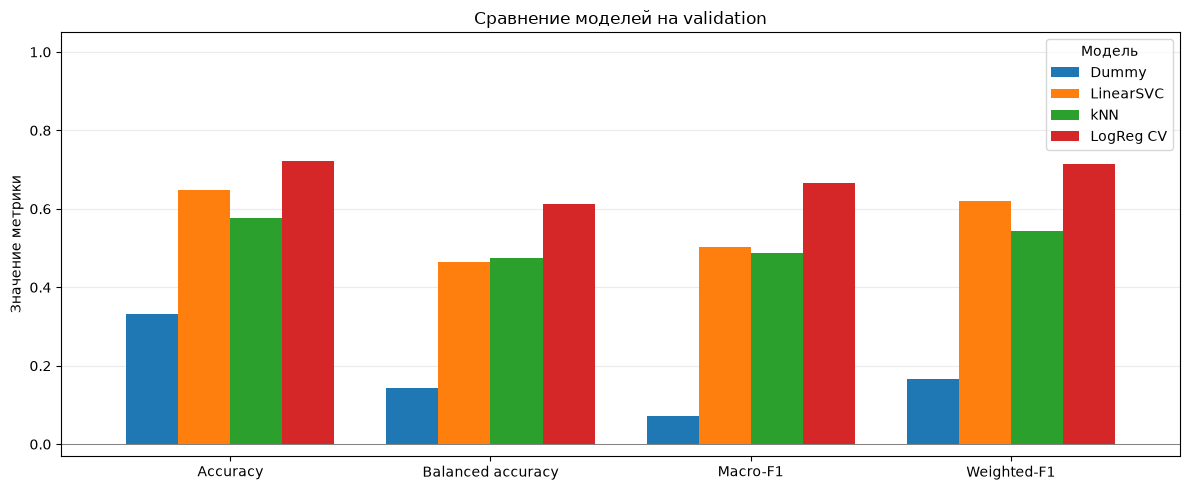

In [ ]:
plot_model_metrics(
    all_metrics,
    [
        'Accuracy',
        'Balanced accuracy',
        'Macro-F1',
        'Weighted-F1',
    ],
)

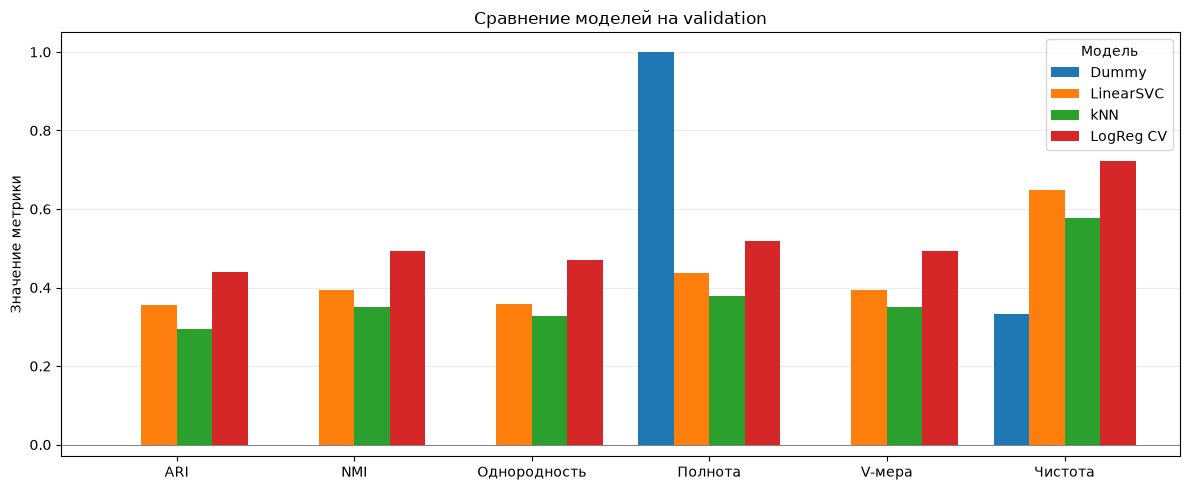

In [ ]:
plot_model_metrics(
    all_metrics,
    [
        'ARI',
        'NMI',
        'Однородность',
        'Полнота',
        'V-мера',
        'Чистота',
    ],
)

# Эксперимент 1
возможно количество реплик пользователей можно сократить, так как часто тема диалога понятна сразу с первого запроса

In [ ]:
y_train = np.asarray(y_train)

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

folds = list(cv.split(
    np.zeros(len(y_train)),
    y_train,
    groups=groups_train,
))


def make_logreg():
    model = clone(model_lr_cv.named_steps['classifier'])
    model.set_params(C=1)
    return model


def cv_topic_score(texts, full_normalize):
    scores = []

    for train_idx, val_idx in folds:
        train_texts = [texts[i] for i in train_idx]
        val_texts = [texts[i] for i in val_idx]

        X_fit, fold_vectorizer = vectorize_topic_texts(
            train_texts,
            full_normalize=full_normalize,
        )
        X_check, _ = vectorize_topic_texts(
            val_texts,
            vectorizer=fold_vectorizer,
            full_normalize=full_normalize,
        )

        model = make_logreg()
        model.fit(X_fit, y_train[train_idx])
        predictions = model.predict(X_check)

        metrics = calculate_metrics(
            y_train[val_idx],
            predictions,
            labels=list(TOPIC_NAMES),
        )
        scores.append(metrics['macro-f1'])

    return np.mean(scores), np.std(scores)

In [ ]:
k_values = [1, 2, 3, 4, 5, None]
results_k = []

for k in k_values:
    texts = [
        parts if k is None else parts[:k]
        for parts in X_train
    ]

    mean_score, std_score = cv_topic_score(
        texts,
        full_normalize=True,
    )

    results_k.append({
        'k': 'Все' if k is None else k,
        'CV Macro-F1': mean_score,
        'Std': std_score,
    })

results_k = pd.DataFrame(results_k)
display(results_k.round(4))

best_k = k_values[int(results_k['CV Macro-F1'].argmax())]
print('Лучшее k:', 'Все' if best_k is None else best_k)

,k,CV Macro-F1,Std
0,1,0.4726,0.0362
1,2,0.5592,0.0398
2,3,0.5664,0.0132
3,4,0.6128,0.0129
4,5,0.6396,0.0278
5,Все,0.6549,0.0200


Лучшее k: Все


In [ ]:
train_texts_k = [
    parts if best_k is None else parts[:best_k]
    for parts in X_train
]
val_texts_k = [
    parts if best_k is None else parts[:best_k]
    for parts in X_val
]

X_train_k, vectorizer_k = vectorize_topic_texts(
    train_texts_k,
    full_normalize=True,
)
X_val_k, _ = vectorize_topic_texts(
    val_texts_k,
    vectorizer=vectorizer_k,
    full_normalize=True,
)

model_lr_k = make_logreg()
model_lr_k.fit(X_train_k, y_train)

y_val_pred_k = model_lr_k.predict(X_val_k)

metrics_k = calculate_metrics(
    y_val,
    y_val_pred_k,
    labels=list(TOPIC_NAMES),
)

print('Validation Macro-F1:', round(metrics_k['macro-f1'], 4))

Validation Macro-F1: 0.667


# Эксперимент 2 
что если нормализация нам только мешает. попробуем без стеммеров и ограничений на длины

In [ ]:
normalize_values = [True, False]
results_normalize = []

for full_normalize in normalize_values:
    mean_score, std_score = cv_topic_score(
        X_train,
        full_normalize=full_normalize,
    )

    results_normalize.append({
        'full_normalize': full_normalize,
        'CV Macro-F1': mean_score,
        'Std': std_score,
    })

results_normalize = pd.DataFrame(results_normalize)
display(results_normalize.round(4))

best_normalize = normalize_values[
    int(results_normalize['CV Macro-F1'].argmax())
]
print('Лучшее full_normalize:', best_normalize)

,full_normalize,CV Macro-F1,Std
0,True,0.6549,0.020
1,False,0.5816,0.025


Лучшее full_normalize: True


In [ ]:
X_train_norm, vectorizer_norm = vectorize_topic_texts(
    X_train,
    full_normalize=best_normalize,
)
X_val_norm, _ = vectorize_topic_texts(
    X_val,
    vectorizer=vectorizer_norm,
    full_normalize=best_normalize,
)

model_lr_norm = make_logreg()
model_lr_norm.fit(X_train_norm, y_train)

y_val_pred_norm = model_lr_norm.predict(X_val_norm)

metrics_norm = calculate_metrics(
    y_val,
    y_val_pred_norm,
    labels=list(TOPIC_NAMES),
)

print('Validation Macro-F1:', round(metrics_norm['macro-f1'], 4))

Validation Macro-F1: 0.667


# Эксперимент 3 
поиграемся с параметрами tf-idf

In [ ]:
results_tfidf = []

for min_df, ngram_range in product(
    [1, 2, 3],
    [(1, 1), (1, 2), (1, 3)],
):
    scores = []

    for train_idx, val_idx in folds:
        train_texts = [X_train[i] for i in train_idx]
        val_texts = [X_train[i] for i in val_idx]

        X_fit, fold_vectorizer = vectorize_topic_texts(
            train_texts,
            min_df=min_df,
            ngram_range=ngram_range,
            full_normalize=True,
        )

        X_check, _ = vectorize_topic_texts(
            val_texts,
            vectorizer=fold_vectorizer,
        )

        model = make_logreg()
        model.fit(X_fit, y_train[train_idx])

        predictions = model.predict(X_check)

        metrics = calculate_metrics(
            y_train[val_idx],
            predictions,
            labels=list(TOPIC_NAMES),
        )
        scores.append(metrics['macro-f1'])

    results_tfidf.append({
        'min_df': min_df,
        'ngram_range': ngram_range,
        'CV Macro-F1': np.mean(scores),
        'Std': np.std(scores),
    })

results_tfidf = pd.DataFrame(results_tfidf).sort_values(
    'CV Macro-F1',
    ascending=False,
).reset_index(drop=True)

display(
    results_tfidf.style
    .format({
        'CV Macro-F1': '{:.4f}',
        'Std': '{:.4f}',
    })
    .background_gradient(
        subset=['CV Macro-F1'],
        cmap='Greens',
    )
)

,min_df,ngram_range,CV Macro-F1,Std
0,2,"(1, 2)",0.6549,0.0200
1,3,"(1, 2)",0.6522,0.0262
2,2,"(1, 1)",0.6515,0.0272
3,3,"(1, 3)",0.6486,0.0276
4,2,"(1, 3)",0.6475,0.0227
5,3,"(1, 1)",0.6394,0.0277
6,1,"(1, 1)",0.6287,0.0217
7,1,"(1, 3)",0.6213,0.0080
8,1,"(1, 2)",0.6129,0.0166


In [ ]:
best_min_df = int(results_tfidf.loc[0, 'min_df'])
best_ngram_range = results_tfidf.loc[0, 'ngram_range']

X_train_best, vectorizer_best = vectorize_topic_texts(
    X_train,
    min_df=best_min_df,
    ngram_range=best_ngram_range,
    full_normalize=True,
)

X_val_best, _ = vectorize_topic_texts(
    X_val,
    vectorizer=vectorizer_best,
)

model_lr_tfidf = make_logreg()
model_lr_tfidf.fit(X_train_best, y_train)

y_val_pred_tfidf = model_lr_tfidf.predict(X_val_best)

metrics_tfidf = calculate_metrics(
    y_val,
    y_val_pred_tfidf,
    labels=list(TOPIC_NAMES),
)

print('Лучший min_df:', best_min_df)
print('Лучший ngram_range:', best_ngram_range)
print('Validation Macro-F1:', round(metrics_tfidf['macro-f1'], 4))

Лучший min_df: 2
Лучший ngram_range: (1, 2)
Validation Macro-F1: 0.667


# Эксперимент 4 
не совсем эксперимент, но в любом случае попрбуем увеличить датасет train искусственно

In [ ]:
TFIDF_PARAMS = {
    'min_df': best_min_df,
    'ngram_range': best_ngram_range,
    'full_normalize': True,
}

pseudo_labels = {}

for line in Path('pseudo_labels_ver3.txt').read_text(
    encoding='utf-8-sig'
).splitlines():
    if line.strip():
        dialog_id, label = line.split()
        pseudo_labels[dialog_id] = int(label)

dialogs_by_id = {
    dialog['dialog_id']: dialog
    for dialog in read_dialogs('hw1_train.jsonl')
}

pseudo_texts = [
    [
        turn['text']
        for turn in dialogs_by_id[dialog_id]['turns']
        if turn['role'] == 'user'
    ]
    for dialog_id in pseudo_labels
]

X_train_expanded = list(X_train) + pseudo_texts

y_train_expanded = np.concatenate([
    np.asarray(y_train),
    np.array(list(pseudo_labels.values()), dtype=int),
])

print('Исходный train:', len(X_train))
print('Добавлено:', len(pseudo_texts))
print('Расширенный train:', len(X_train_expanded))

Исходный train: 971
Добавлено: 3
Расширенный train: 974


In [ ]:
experiment_data = {
    'Исходный train': (X_train, y_train),
    'Train + псевдоразметка': (
        X_train_expanded,
        y_train_expanded,
    ),
}

models_expansion = {}
vectorizers_expansion = {}
metrics_expansion = {}

metric_keys = [
    'accuracy',
    'balanced_accuracy',
    'macro-f1',
    'weighted-f1',
]

for name, (train_texts, train_labels) in experiment_data.items():
    X_fit, current_vectorizer = vectorize_topic_texts(
        train_texts,
        **TFIDF_PARAMS,
    )

    X_check, _ = vectorize_topic_texts(
        X_val,
        vectorizer=current_vectorizer,
    )

    current_model = make_logreg()
    current_model.fit(X_fit, train_labels)

    predictions = current_model.predict(X_check)

    metrics = calculate_metrics(
        y_val,
        predictions,
        labels=list(TOPIC_NAMES),
    )

    models_expansion[name] = current_model
    vectorizers_expansion[name] = current_vectorizer
    metrics_expansion[name] = metrics


comparison_expansion = pd.DataFrame({
    name: {
        key: metrics[key]
        for key in metric_keys
    }
    for name, metrics in metrics_expansion.items()
})

display(
    comparison_expansion.style
    .format('{:.4f}')
    .background_gradient(cmap='Greens', axis=1)
)

,Исходный train,Train + псевдоразметка
accuracy,0.7212,0.7115
balanced_accuracy,0.6135,0.5923
macro-f1,0.6670,0.6466
weighted-f1,0.7151,0.7037


In [ ]:
per_class_expansion = pd.DataFrame({
    name: {
        f'{label}: {topic}': metrics['per_class_metrics'][f'f1_{label}']
        for label, topic in TOPIC_NAMES.items()
    }
    for name, metrics in metrics_expansion.items()
})

display(
    per_class_expansion.style
    .format('{:.4f}')
    .background_gradient(cmap='Greens', axis=1)
)

,Исходный train,Train + псевдоразметка
0: Программирование,0.9318,0.9318
1: Вопросы про ИИ,0.7500,0.7500
2: Перевод и работа с языками,0.4348,0.3636
3: Работа с текстом,0.7310,0.7310
4: Объяснение и разъяснение,0.6325,0.6218
"5: Математика, расчеты, решение задач",0.4615,0.4615
6: Прочее,0.7273,0.6667


In [ ]:
best_expansion_name = max(
    metrics_expansion,
    key=lambda name: metrics_expansion[name]['macro-f1'],
)

best_logreg = models_expansion[best_expansion_name]
best_vectorizer = vectorizers_expansion[best_expansion_name]

print('Выбранный вариант:', best_expansion_name)
print(
    'Validation Macro-F1:',
    round(
        metrics_expansion[best_expansion_name]['macro-f1'],
        4,
    ),
)

Выбранный вариант: Исходный train
Validation Macro-F1: 0.667


# Тест

In [ ]:
X_test_best, _ = vectorize_topic_texts(
    X_test,
    vectorizer=best_vectorizer,
)

y_test_pred = best_logreg.predict(X_test_best)

metrics_test = calculate_metrics(
    y_test,
    y_test_pred,
    labels=list(TOPIC_NAMES),
)

print('Модель:', best_expansion_name)

display(
    pd.DataFrame({
        'Test': {
            key: metrics_test[key]
            for key in metric_keys
        }
    }).style.format('{:.4f}')
)

display(
    pd.DataFrame({
        'Precision': [
            metrics_test['per_class_metrics'][f'precision_{label}']
            for label in TOPIC_NAMES
        ],
        'Recall': [
            metrics_test['per_class_metrics'][f'recall_{label}']
            for label in TOPIC_NAMES
        ],
        'F1': [
            metrics_test['per_class_metrics'][f'f1_{label}']
            for label in TOPIC_NAMES
        ],
        'Число примеров': [
            np.sum(np.asarray(y_test) == label)
            for label in TOPIC_NAMES
        ],
    }, index=[
        f'{label}: {topic}'
        for label, topic in TOPIC_NAMES.items()
    ]).style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}',
        'Число примеров': '{:d}',
    })
)